In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib import cm
import plotly.express as px
import plotly.graph_objects as go

# The two cylinder problem

In [ ]:
#With RB I mean Ruiz and Basqurotto paper
#------------------PARAMETERS---------------------------
I1 = 1.0
I2 = 1.5
T_START = 0.0
T_END = 30.0
N_POINTS = 5000

#-------------------- MODEL-----------------------------
#Some info: #theta1, theta2 = body orientations
#           #omega1, omega2 0 angular velocities
            #state = [theta1, theta2, omega1, omega2]
            #tau 0 torque
def torque(relative_angle):       #like the trig example in RB
    return np.sin(relative_angle)

def equations_of_motion(t, state):
    theta1, theta2, omega1, omega2 = state
    relative_angle = theta1 - theta2
    tau = torque(relative_angle)
    dtheta1_dt = omega1
    dtheta2_dt = omega2
    domega1_dt = tau / I1
    domega2_dt = -tau / I2

    return [
        dtheta1_dt,
        dtheta2_dt,
        domega1_dt,
        domega2_dt
    ]

#-------------------CONSERVED STUFF---------------------------
def angular_momentum(omega1, omega2):
    return I1 * omega1 + I2 * omega2

def energy(theta1, theta2, omega1, omega2):
    #s = theta1-theta2
    kinetic = 0.5 * I1 * omega1**2 + 0.5 * I2 * omega2**2
    potential = np.cos(theta1 - theta2)
    return kinetic + potential

#-----------------------SIMULATION-----------------------------
def simulate(initial_state, t_start=T_START, t_end=T_END, N_points=N_POINTS, events=None):
    times = np.linspace(
        t_start,
        t_end,
        int(N_points)
    )
    solution = solve_ivp(
        equations_of_motion,
        (t_start, t_end),
        initial_state,
        t_eval=times,
        events=events,
        rtol=1e-10,
        atol=1e-12
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    return solution

#-------------------POINCARE SECTIONS---------------------------
def generate_ICs(E, N_ics=15):
    """
    Given a fixed energy level E, generate a spread of N_ics initial
    conditions that have the desired energy level.
    """
    # Generate possible initial conditions
    theta1_vals = np.linspace(-np.pi, np.pi, 100)
    # Take valid initial conditions where potential isn't larger than total energy E
    valid_ics = np.cos(theta1_vals)<=E
    #print(f"Removing {np.sum(~valid_ics)} ICs: {theta1_vals[~valid_ics]}")
    theta1_vals = theta1_vals[valid_ics]
    print(f"{len(theta1_vals)} valid ICs remaining")
    # Take N_ics total if we have a lot left
    if len(theta1_vals)>N_ics:
        selected = np.linspace(0, len(theta1_vals)-1, N_ics).astype(np.int16)
        #print(selected, len(selected))
        theta1_vals = theta1_vals[selected]
    elif len(theta1_vals) == 0:
        raise ValueError(f"Specified energy {E} results in no valid ICs")
    print(f"Selecting {N_ics} vals: {theta1_vals}")
    # From these initial theta1 values, generate states of the system
    # Set w1 = 0, theta2 = 0 and put remaining energy into w2
    initial_states = np.zeros((len(theta1_vals), 4))
    for i in range(len(theta1_vals)):
        # Compute omega2 from Hamiltonian
        omega1_0 = 0.0
        omega2_0 = np.sqrt((2/I2)*(E - 0.5*I1*omega1_0**2 - np.cos(theta1_vals[i])))
        initial_states[i, :] = np.array([theta1_vals[i], 0.0, omega1_0, omega2_0])
        print(f"Energy of state: {energy(*initial_states[i, :])}")
    return initial_states


# Poincare sections
def Poincare_section(initial_states, E=None, tf=1000):
    """Integrate each initial state to time tf from each of these initial points and keep track of the
    state of the system every time we cross the section. Plot the resulting
    crossings for all initial conditions.
    """
    # Event function to detect trajectories crossing theta2=0 (mod 2pi) when omega2>0
    # Scipy solve_ivp will note when this function has a zero
    def event_theta2_zero(t, state):
        return np.sin(state[1]/2) # Will be zero whenever theta2=0 (mod 2pi)
    # Attach attribute saying crossings should be in just one direction
    event_theta2_zero.direction = 1

    # For each initial theta1, compute corresponding ICs of theta2
    # omega1, and omega2. 
    # Start at Poincare section where theta2=0 and suppose we start with omega1=0
    plt.figure(figsize=(8, 6))
    for i in range(len(initial_states)):
        initial_state = initial_states[i, :]
        # Simulate for a long time collecting events when theta2 crosses zero
        t0 = 0
        sol = simulate(initial_state, t0, tf, 100, events=event_theta2_zero)
        if len(sol.y_events[0]) > 0:
            print(f"{len(sol.y_events[0])} crossings for state: {initial_state}")
            theta1_crossings = sol.y_events[0][:, 0]
            omega1_crossings = sol.y_events[0][:, 2]
            plt.scatter(theta1_crossings%(2*np.pi), omega1_crossings, s=5, alpha=0.9)
        else:
            print(f"WARNING: no crossings detected for initial state {initial_state}")
        
    plt.xlabel(r"$\theta_1$")
    plt.ylabel(r"$\omega_1$")
    plt.title(rf"Poincaré Section ($\theta_2=0,\,\omega_2>0$) at $E={E}$")
    plt.show()

#-------------------LYAPUNOV EXPONENTS---------------------------
def separation_plot_coupled(system_equations, initial_state, tf=5000, dt=1, eps=1e-8, plot_eps_expansion=True):
    """
    Given an initial state, make a perturbation of size eps. Integrate both systems
    and plot the delta between them at each dt value. The slope of the line in a natural
    log of delta vs time plot is approximately the Lyapunov exponent. Uses coupled system
    to ensure evaluation at the same times, plus general implementation allowing integration
    of any system.
    If plot_eps_expansion is True, we also plot the ratio delta/eps to see how quickly
    a perturbation of size eps expands.
    """
    def coupled_system(t, state):
        # First half is system 1, second system 2
        state1 = state[:len(state)//2]
        state2 = state[len(state)//2:]
        rhs1 = system_equations(t, state1)
        rhs2 = system_equations(t, state2)
        return np.concatenate([rhs1, rhs2])
    
    perturbation = np.random.randn(len(initial_state))
    # Create new initial condition a distance eps away
    xprime = initial_state + eps*perturbation/np.linalg.norm(perturbation)
    # Simulate both
    coupled_state = np.concatenate([initial_state, xprime])
    sol = solve_ivp(
            coupled_system,
            [0, tf],
            coupled_state,
            t_eval=np.arange(0, tf+dt, dt),
            rtol=1e-10,
            atol=1e-13
        )
    # Deltas
    y_original = sol.y[:len(initial_state), :]
    y_prime = sol.y[len(initial_state):, :]
    deltas = np.linalg.norm(y_original-y_prime, axis=0)
    # Plot
    plt.figure(figsize=(8, 6))
    plt.plot(sol.t, np.log(deltas))
    plt.plot(sol.t, sol.t+np.log(deltas)[0], ls='--', c='k', label="Slope 1")
    early_end = 75
    early_slope = (np.log(deltas)[early_end]-np.log(deltas)[0])/(early_end)
    plt.plot(sol.t, early_slope*sol.t+np.log(deltas)[0], ls='-.', c='k', label=f"Slope {early_slope:.3f}")
    plt.plot([0, tf], np.ones(2)*np.log(deltas)[0], ls='--', c='k')
    plt.ylim(bottom=-2+np.min(np.log(deltas)), top=5+np.max(np.log(deltas)))
    #plt.xlim((0, 200))
    plt.xlabel("t")
    plt.ylabel(r"$\log|\delta x|$")
    plt.title("Delta of separation between trajectories")
    plt.legend()
    plt.show()
    # eps expansion
    if plot_eps_expansion:
        plt.figure(figsize=(8, 6))
        plt.plot(sol.t, deltas/eps)
        #plt.plot(sol.t, sol.t+np.log(deltas)[0], ls='--', c='k')
        #plt.plot([0, tf], np.ones(2)*np.log(deltas)[0], ls='--', c='k')
        plt.xlim((0, 1000))
        #plt.ylim((0, 1000))
        plt.xlabel("t")
        plt.ylabel(r"$|\delta x|/\varepsilon$")
        plt.title("Relative separation between trajectories")
        plt.show()

def Lyapunov_exponent_coupled(system_equations, initial_state, tf=1000, dt=0.5, eps=1e-8, drop_transient=True, adaptive_rescaling=False, plotting=True):
    """
    Given an initial state, make a perturbation of size eps. Integrate both systems
    together as a coupled system (they don't interact, but are evaluated at the same times)
    saving deltas at each time step. Rescale the perturbation at each step to more
    accurately capture the Lyapunov exponent. Following book pg 116.
    If drop_transient is True, we discard the first 15% of deltas, giving time for
    the initial condition to stabilize.
    If adaptive_rescaling is True, we rescale the perturbation when it has increased by 100x.
    """
    def coupled_system(t, state):
        # First half is system 1, second system 2
        state1 = state[:len(state)//2]
        state2 = state[len(state)//2:]
        rhs1 = system_equations(t, state1)
        rhs2 = system_equations(t, state2)
        return np.concatenate([rhs1, rhs2])
    
    perturbation = np.random.randn(len(initial_state))
    # Create new initial condition a distance eps away
    xprime = initial_state + eps*perturbation/np.linalg.norm(perturbation)
    time = 0
    T = dt
    x = initial_state.copy()
    # Coupled state
    coupled_state = np.concatenate([x, xprime])
    deltas = []
    while time < tf:
        if time+dt > tf:
            dt = tf-time
        sol = solve_ivp(
            coupled_system,
            [0, dt],
            coupled_state,
            rtol=1e-10,
            atol=1e-13
        )
        final_state = sol.y[:, -1]
        x = final_state[:len(final_state)//2]
        xprime = final_state[len(final_state)//2:]
        delta = x-xprime
        deltas.append(np.linalg.norm(delta))
        if adaptive_rescaling:
            # Rescale the delta to mag eps and form new initial condition
            if deltas[-1]/eps > 10**2:
                xprime = x + eps*delta/deltas[-1]  
        else: # Rescale every step
            xprime = x + eps*delta/deltas[-1]

        if np.linalg.norm(deltas[-1]) > 1e15:
            print("WARNING: trajectory diverged. Possibly due to too high energy.")
            break
            #print(f"State: x:{x}, xprime:{xprime}")
        coupled_state = np.concatenate([x, xprime])
        time += dt
    if plotting:
        plt.figure(figsize=(8, 6))
        plt.plot(np.linspace(0, tf, len(deltas)), np.log(deltas), linewidth=0.5, alpha=0.7)
        #plt.plot(sol.t, sol.t+np.log(deltas)[0], ls='--', c='k')
        #plt.plot([0, tf], np.ones(2)*np.log(deltas)[0], ls='--', c='k')
        plt.xlabel("t")
        plt.ylabel(r"$|\delta x|$")
        plt.show()
    # The Lyapunov exponent is then the limit as this process goes to infinity
    # of (1/NT) * sum_j( ln(d_j / eps))
    # where j goes from 1 to N, d_j is the jth delta, and eps is the
    # size of the original perturbation. T is the time step.
    if drop_transient:
        # Drop first 15% as start up
        dropped_ind = int(len(deltas)/(100/15))
        L_exponent = np.sum(np.log(np.array(deltas[dropped_ind:])/eps)) / len(deltas[dropped_ind:]) / T
    else:
        L_exponent = np.sum(np.log(np.array(deltas)/eps)) / len(deltas) / T
    return L_exponent

#--------------------------ANALYSIS-------------------------------
def analyse(solution):
    theta1 = solution.y[0]
    theta2 = solution.y[1]
    omega1 = solution.y[2]
    omega2 = solution.y[3]
    relative_angle = theta1 - theta2
    relative_velocity = omega1 - omega2
    L = angular_momentum(omega1, omega2)
    E = energy(theta1, theta2, omega1, omega2)
    print("\nSimulation Information")
    print(
        f"Maximum |angular momentum|: "
        f"{np.max(np.abs(L)):.3e}"
    )

    print(
        f"Maximum energy deviation: "
        f"{np.max(np.abs(E - E[0])):.3e}"
    )

    return relative_angle, relative_velocity, L, E

In [3]:
#------------------ INITIAL CONDITIONS ----------------------
initial_state = [
    0.0,
    0.1,
    0.0,
    0.0
]

solution = simulate(initial_state)
relative_angle, relative_velocity, L, E = analyse(solution)
theta1 = solution.y[0]
theta2 = solution.y[1]
omega1 = solution.y[2]
omega2 = solution.y[3]


Simulation Information
Maximum |angular momentum|: 1.554e-15
Maximum energy deviation: 1.358e-09


In [220]:
initial_state = [
    1.6818,
    0.0,
    0.0,
    0.5302
]

solution = simulate(initial_state, t_end=100)
relative_angle, relative_velocity, L, E = analyse(solution)
theta1 = solution.y[0]
theta2 = solution.y[1]
omega1 = solution.y[2]
omega2 = solution.y[3]


Simulation Information
Maximum |angular momentum|: 7.953e-01
Maximum energy deviation: 1.442e-08


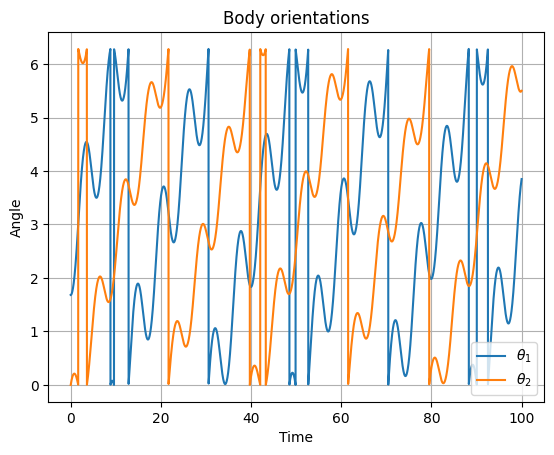

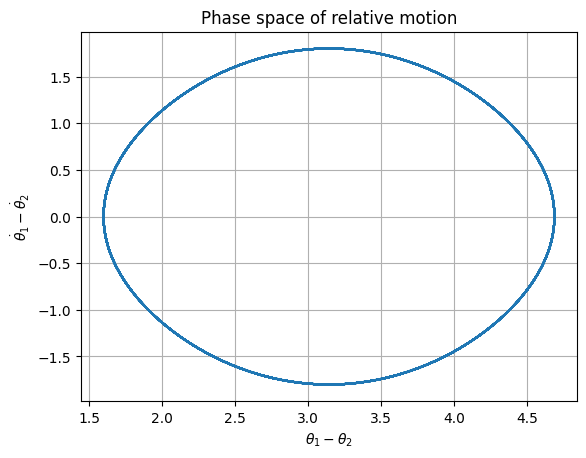

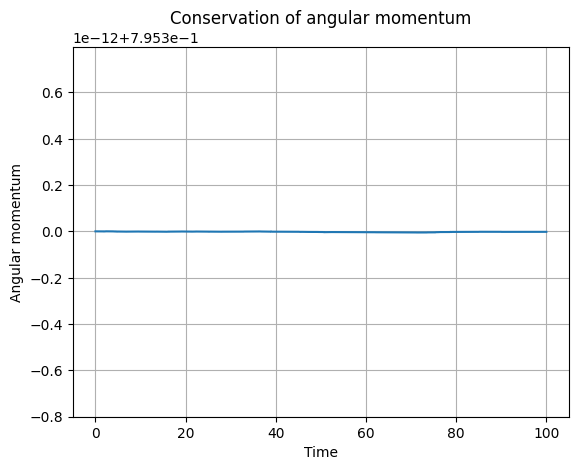

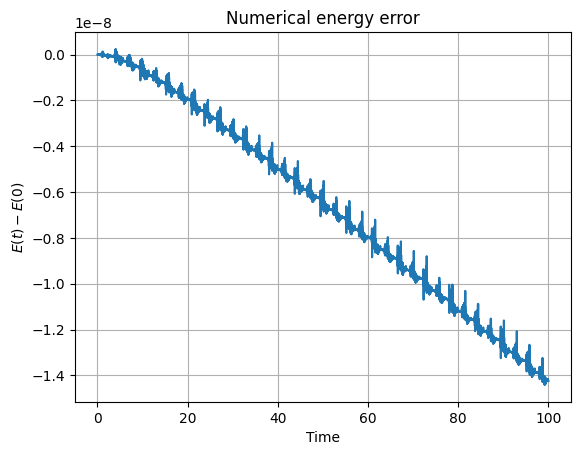

In [221]:
#-----------------PLOTS----------------------

#Body orientations
plt.figure()
plt.plot(solution.t, theta1%(2*np.pi), label=r"$\theta_1$")
plt.plot(solution.t, theta2%(2*np.pi), label=r"$\theta_2$")
plt.xlabel("Time")
plt.ylabel("Angle")
plt.title("Body orientations")
plt.legend()
plt.grid()
plt.show()

#Phase space
plt.figure()
plt.plot(relative_angle, relative_velocity)
plt.xlabel(r"$\theta_1-\theta_2$")
plt.ylabel(r"$\dot{\theta}_1-\dot{\theta}_2$")
plt.title("Phase space of relative motion")
plt.grid()
plt.show()

#Angular momentum
plt.figure()
plt.plot(solution.t, L)
plt.xlabel("Time")
plt.ylabel("Angular momentum")
plt.title("Conservation of angular momentum")
plt.grid()
plt.show()

#Energy
plt.figure()
plt.plot(solution.t, E - E[0])
plt.xlabel("Time")
plt.ylabel(r"$E(t)-E(0)$")
plt.title("Numerical energy error")
plt.grid()
plt.show()

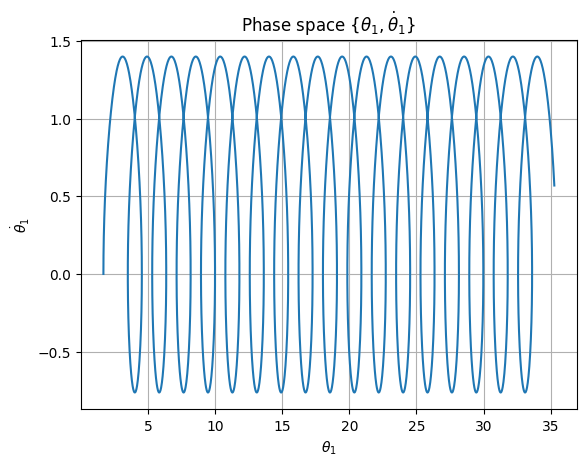

In [222]:
plt.figure()
plt.plot(theta1, omega1)
#plt.plot(theta2, omega2, label=r"")
plt.xlabel(r"$\theta_1$")
plt.ylabel(r"$\dot{\theta}_1$")
plt.title(r"Phase space $\{\theta_1, \dot{\theta}_1\}$")
#plt.legend()
plt.grid()
plt.show()

## Poincare Sections

In [336]:
E = 0.5
initial_states = generate_ICs(E=E, N_ics=10)

67 valid ICs remaining
Selecting 10 vals: [-3.14159265 -2.69732703 -2.2530614  -1.74532925 -1.30106362  1.23759711
  1.74532925  2.18959488  2.63386051  3.14159265]
Energy of state: 0.5000000000000004
Energy of state: 0.4999999999999999
Energy of state: 0.4999999999999999
Energy of state: 0.5
Energy of state: 0.5
Energy of state: 0.5
Energy of state: 0.5
Energy of state: 0.4999999999999998
Energy of state: 0.5000000000000001
Energy of state: 0.5000000000000004


68 crossings for state: [-3.14159265  0.          0.          1.41421356]
66 crossings for state: [-2.69732703  0.          0.          1.36768736]
59 crossings for state: [-2.2530614   0.          0.          1.22776364]
53 crossings for state: [-1.74532925  0.          0.          0.94773286]
44 crossings for state: [-1.30106362  0.          0.          0.55800381]
43 crossings for state: [1.23759711 0.         0.         0.48018335]
54 crossings for state: [1.74532925 0.         0.         0.94773286]
58 crossings for state: [2.18959488 0.         0.         1.20003162]
65 crossings for state: [2.63386051 0.         0.         1.35343975]
68 crossings for state: [3.14159265 0.         0.         1.41421356]


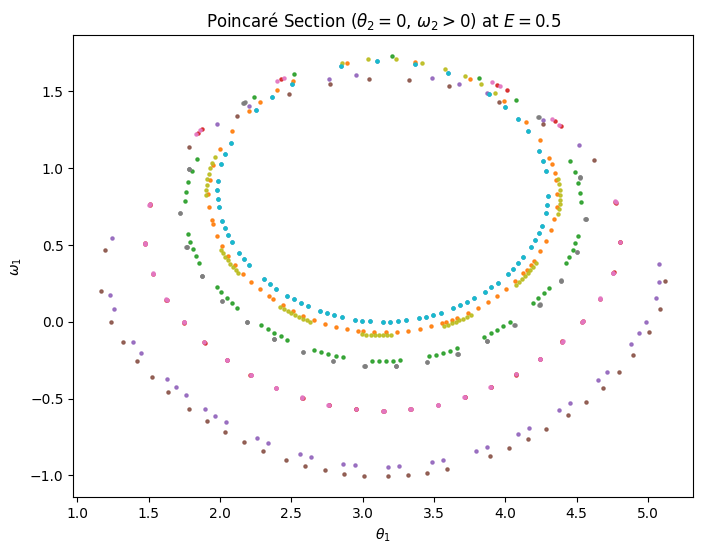

In [314]:
# Testing
Poincare_section(initial_states, E=E, tf=1000)

## Lyapunov exponents

In [ ]:
# Average from the same initial state (random initial perturbations)
avg = 0
runs = 5
for i in range(runs):
    L_exponent = Lyapunov_exponent_coupled(
        equations_of_motion,
        initial_state, 
        tf=10000, 
        dt=0.5, 
        drop_transient=True, 
        adaptive_rescaling=False,
        plotting=False
    )
    print(f"Lyapunov exponent: {L_exponent:.3e}")
    avg += L_exponent / runs
print(f"Average over the runs: {avg:.3e}")

Lyapunov exponent: 2.335e-04
Lyapunov exponent: 4.175e-04
Lyapunov exponent: 3.047e-04
Lyapunov exponent: 4.983e-04
Lyapunov exponent: 5.275e-04
Average over the runs: 3.963e-04


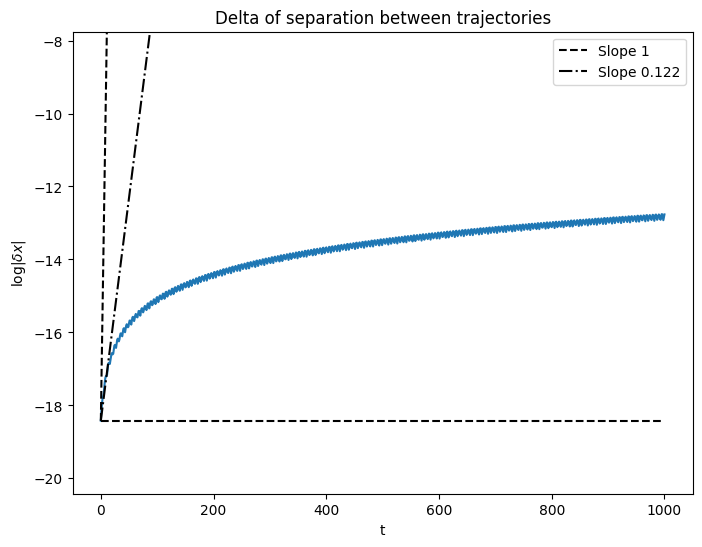

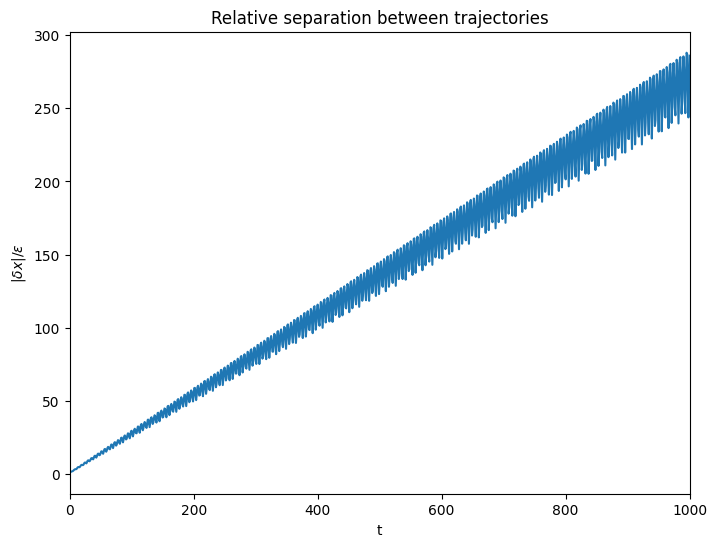

In [349]:
separation_plot_coupled(equations_of_motion, initial_states[1], tf=1000, dt=1)

# The three cylinder problem

Since the two cylinder problem is integrable (it has two DoF and two constants of motion: total energy and total angular momentum), it is not a chaotic system. If we add a third cylinder, linked to the second by a similar coupling potential based on relative angles, we can create a non-integrable system. This system has three DoF, but only the same two constants of motion. This system now has the potential for chaos.

In [ ]:
class ThreeCylinderProblem():
    def __init__(self, Is=np.array([1.0, 1.25, 0.75]), E=0.5):
        """
        The three cylinder problem:
        Is: Moments of inertia of the three cylinders
        E: Total energy of the system
        """
        self.Is = Is
        self.E = E

    #-------------------- MODEL-----------------------------
    def torques(self, thetas):
        theta1, theta2, theta3 = thetas
        torque1 = np.sin(theta1-theta2)
        torque2 = np.sin(theta2-theta3)
        return torque1, torque2

    def potential(self, thetas):
        theta1, theta2, theta3 = thetas
        return np.cos(theta1-theta2) + np.cos(theta2-theta3)
    
    def equations_of_motion(self, t, state):
        thetas = state[:len(state)//2]
        omegas = state[len(state)//2:]
        tau1, tau2 = self.torques(thetas)
        return [
            omegas[0],
            omegas[1],
            omegas[2],
            tau1 / self.Is[0],
            (-tau1+tau2) / self.Is[1],
            -tau2 / self.Is[2],
        ]
    #-------------------CONSERVED STUFF---------------------------

    def angular_momentum(self, omegas):
        return np.dot(self.Is, omegas)

    def energy(self, state):
        thetas = state[:len(state)//2]
        omegas = state[len(state)//2:]
        T = 0.5*np.dot(self.Is, omegas**2)
        V = self.potential(thetas)
        return T+V
    #-----------------------SIMULATION-----------------------------
    def simulate(self, initial_state, t_start=0, t_end=T_END, N_points=100, events=None):
        times = np.linspace(
            t_start,
            t_end,
            int(N_points)
        )
        solution = solve_ivp(
            self.equations_of_motion,
            (t_start, t_end),
            initial_state,
            t_eval=times,
            events=events,
            rtol=1e-10,
            atol=1e-12
        )

        if not solution.success:
            raise RuntimeError(solution.message)

        return solution
    #--------------------------ANALYSIS-------------------------------
    def analyse(self, solution):
        states = solution.y
        L = np.zeros(states.shape[1])
        E = np.zeros(states.shape[1])
        for i in range(states.shape[1]):
            L[i] = self.angular_momentum(states[states.shape[0]//2:, i])
            E[i] = self.energy(states[:, i])
        print("\nSimulation Information")
        print(
            f"Maximum |angular momentum|: "
            f"{np.max(np.abs(L)):.3e}"
        )

        print(
            f"Maximum energy deviation: "
            f"{np.max(np.abs(E - E[0])):.3e}"
        )

        return L, E

    #-------------------POINCARE SECTIONS---------------------------

    def Poincare_ICs(self, N_ics=15):
        """
        Given a fixed energy level E specified in the constructor, generate a spread of N_ics initial
        conditions that have the desired energy level.
        """
        E = self.E
        # Generate possible initial conditions
        theta1_vals = np.linspace(-np.pi, np.pi, 100)
        # Start all other thetas at 0
        theta2 = 0.0
        theta3 = 0.0
        # Take valid initial conditions where potential isn't larger than total energy E
        valid_ics = np.zeros(len(theta1_vals), dtype=np.bool_)
        for i in range(len(theta1_vals)):
            if self.potential([theta1_vals[i], theta2, theta3]) <= E:
                valid_ics[i] = 1
        #print(f"Removing {np.sum(~valid_ics)} ICs: {theta1_vals[~valid_ics]}")
        theta1_vals = theta1_vals[valid_ics]
        print(f"{len(theta1_vals)} valid ICs remaining")
        # Take N_ics total if we have a lot left
        if len(theta1_vals)>N_ics:
            selected = np.linspace(0, len(theta1_vals)-1, N_ics).astype(np.int16)
            #print(selected, len(selected))
            theta1_vals = theta1_vals[selected]
        elif len(theta1_vals) == 0:
            raise ValueError(f"Specified energy {E} results in no valid ICs")
        print(f"Selecting {N_ics} vals: {theta1_vals}")
        # From these initial theta1 values, generate states of the system
        # Set w1=0
        # Split the remaining energy evenly into the angular momentum
        # of cylinders 2 and 3
        omegas = np.zeros(3)
        initial_states = np.zeros((len(theta1_vals), 6))
        for i in range(len(theta1_vals)):
            # Use Hamiltonion to compute w2 and w3
            # First, the shared angular momentum
            thetas = np.array([theta1_vals[i], theta2, theta3])
            L_0 = np.sqrt(2*(E-self.potential(thetas)) * self.Is[1]*self.Is[2]/(self.Is[1]+self.Is[2]))
            # Then L=Iw, so w=L/I for each cylinder
            omegas[1] = L_0 / self.Is[1]
            omegas[2] = L_0 / self.Is[2]
            initial_states[i, :] = np.concatenate((thetas, omegas))
            print(f"Energy of state: {self.energy(initial_states[i, :])}")
        return initial_states

    # Poincare sections
    def Poincare_section(self, initial_states, tf=1000, plotting_method='color'):
        """Integrate the system to time tf from each of the given initial conditions,
        keeping track of the state of the system every time we cross the section. 
        Plot the resulting crossings for all initial conditions.
        Plotting methods: ['color', 'slice', '3D', '3Dinteractive']
        Method "color" plots the theta1, omega1 intersections with omega3 used to color
        each point and theta3, omega3 with omega1 used to color. 
        Regular motion should result in a smooth color transition across
        a region, while chaos gives random looking colors.
        Method "slice" plots theta1, omega1 intersections and theta3, omega3 intersections
        with |theta3|<eps and |theta1|<eps respectively.
        Method 3D generates nice matplotlib 3D plot theta1, omega1, theta3 for saving
        Method 3D interactive does the same but using plotly so you can interact with it
        """
        # Event function to detect trajectories crossing theta2=0 (mod 2pi) when omega2>0
        # Scipy solve_ivp will note when this function has a zero
        def intersection_event(t, state):
            return np.sin(state[1]/2) # Will be zero whenever theta2=0 (mod 2pi)
        # Attach attribute saying crossings should be in just one direction
        intersection_event.direction = 1 #TODO decide whether this should just be 0
        if plotting_method == 'color' or plotting_method == 'slice':
            fig, axes = plt.subplots(1, 2, figsize=(12, 6))
        elif plotting_method == '3Dinteractive':
            fig = go.Figure()
        elif plotting_method == '3D':
            # fig = plt.figure(dpi=300) # For high res figs
            fig = plt.figure(dpi=150)
            ax = fig.add_subplot(111, projection='3d')
        else:
            plt.figure(figsize=(9, 6))
        eps = 0.5 # Slicing epsilon
        # Start at given Ics
        for i in range(initial_states.shape[0]):
            # Initial state
            initial_state = initial_states[i, :]
            # Simulate for a long time collecting events when theta2 crosses zero
            t0 = 0
            sol = solve_ivp(
                self.equations_of_motion,
                [t0, tf],
                initial_state,
                events=intersection_event,
                rtol=1e-9,
                atol=1e-9
            )
            if len(sol.y_events[0]) > 0:
                print(f"{len(sol.y_events[0])} crossings for state: {initial_state}")
                #print(sol.y_events[0].shape)
                theta1_crossings = sol.y_events[0][:, 0]
                theta3_crossings = sol.y_events[0][:, 2]
                omega1_crossings = sol.y_events[0][:, 3]
                omega3_crossings = sol.y_events[0][:, 5]
                if plotting_method == 'color':
                    # Generate plot theta1, omega1 colored by omega3
                    axes[0].scatter(theta1_crossings%(2*np.pi), omega1_crossings, s=5, alpha=0.9, c=omega3_crossings, cmap='hsv')
                    # Generate plot theta3, omega3 colored by omega1
                    axes[1].scatter(theta3_crossings%(2*np.pi), omega3_crossings, s=5, alpha=0.9, c=omega1_crossings, cmap='hsv')
                elif plotting_method == 'slice':
                    # Plot theta1, omega1 but only where theta3 is close enough to 0 (mod 2pi)
                    slice_indices = np.logical_or(theta3_crossings%(2*np.pi) < eps, -1*theta3_crossings%(2*np.pi) < eps)
                    axes[0].scatter(theta1_crossings[slice_indices]%(2*np.pi), omega1_crossings[slice_indices], s=10, alpha=0.9)
                    # Plot theta3, omega3 but only where theta1 is close enough to 0 (mod 2pi)
                    slice_indices = np.logical_or(theta1_crossings%(2*np.pi) < eps, -1*theta1_crossings%(2*np.pi) < eps)
                    axes[1].scatter(theta3_crossings[slice_indices]%(2*np.pi), omega3_crossings[slice_indices], s=10, alpha=0.9)
                elif plotting_method == '3D':
                    # Generate plot theta1, omega1, theta3
                    scatter = ax.scatter3D(theta1_crossings%(2*np.pi), omega1_crossings, theta3_crossings%(2*np.pi), s=10, alpha=0.9)
                elif plotting_method == '3Dinteractive':
                    # Plot theta1, omega1, theta3
                    fig.add_scatter3d(
                        x=theta1_crossings%(2*np.pi), 
                        y=omega1_crossings, 
                        z=theta3_crossings%(2*np.pi), 
                        mode='markers',
                        marker=dict(
                            size=5,
                            opacity=0.8,
                        )
                    )
            else:
                print(f"WARNING: no crossings detected for initial state {initial_state}")
        if plotting_method == 'color':
            axes[0].set_xlabel(r"$\theta_1$")
            axes[0].set_ylabel(r"$\omega_1$")
            axes[1].set_xlabel(r"$\theta_3$")
            axes[1].set_ylabel(r"$\omega_3$")
            fig.suptitle(rf"Poincaré Sections ($\theta_2=0,\,\omega_2>0$) at $E={self.E}$")
            plt.show()
        elif plotting_method == 'slice':
            axes[0].set_xlabel(r"$\theta_1$")
            axes[0].set_ylabel(r"$\omega_1$")
            axes[0].set_title(rf"Sliced, $|\theta_3|<{eps}$")
            axes[1].set_xlabel(r"$\theta_3$")
            axes[1].set_ylabel(r"$\omega_3$")
            axes[1].set_title(rf"Sliced, $|\theta_1|<{eps}$")
            fig.suptitle(rf"Poincaré Sections ($\theta_2=0,\,\omega_2>0$) at $E={self.E}$")
            plt.show()
        elif plotting_method == '3D':
            # View angle
            ax.view_init(elev=25, azim=-125)
            ax.set_xlabel(r"$\theta_1$")
            ax.set_ylabel(r"$\omega_1$")
            zlabel = ax.set_zlabel(r"$\theta_3$")
            suptitle = ax.set_title(f"Poincaré Section at E={self.E}, projected to 3D")
            # For saving plots
            # elevs = [25, 90, 0, 0]
            # azims = [-125, -90, -90, 0]
            # for i in range(len(azims)):
            #     ax.view_init(elev=elevs[i], azim=azims[i])
            #     plt.savefig(
            #         rf"YOURPATHHERE", 
            #         bbox_inches='tight',
            #         bbox_extra_artists=[zlabel, suptitle],
            #     )
            plt.show()
        elif plotting_method == '3Dinteractive':
            fig.update_layout(
                #margin=dict(l=1, r=1.1, b=1.1, t=1.1),
                width=650,
                height=500,
                autosize=True,
                title=dict(
                    text=f"Poincaré Section at E={self.E}, projected to 3D"
                ),
                scene = dict(
                    xaxis=dict(
                        title=dict(
                            text=r"theta1"
                        )
                    ),
                    yaxis=dict(
                        title=dict(
                            text=r"w1"
                        )
                    ),
                    zaxis=dict(
                        title=dict(
                            text=r"theta3"
                        )
                    ),
                )         
            )
            fig.show()
        else:
            plt.xlabel(r"$\theta_1$")
            plt.ylabel(r"$\omega_1$")
            plt.title(rf"Poincaré Section ($\theta_2=0,\,\omega_2>0$) at $E={self.E}$")
            plt.show()
    

In [350]:
problem = ThreeCylinderProblem(E=1)
initial_states = problem.Poincare_ICs(N_ics=10)

50 valid ICs remaining
Selecting 10 vals: [-3.14159265 -2.82426006 -2.50692747 -2.12612836 -1.80879577  1.74532925
  2.06266184  2.44346095  2.76079354  3.14159265]
Energy of state: 1.0
Energy of state: 1.0
Energy of state: 1.0
Energy of state: 1.0
Energy of state: 1.0
Energy of state: 1.0
Energy of state: 0.9999999999999999
Energy of state: 0.9999999999999998
Energy of state: 1.0
Energy of state: 1.0



Simulation Information
Maximum |angular momentum|: 1.936e+00
Maximum energy deviation: 1.848e-08


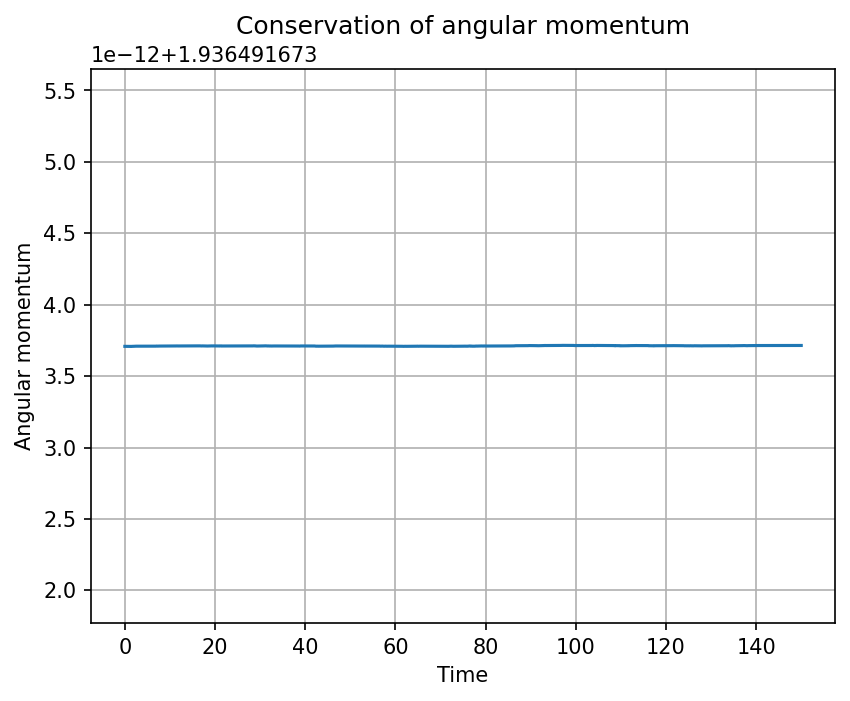

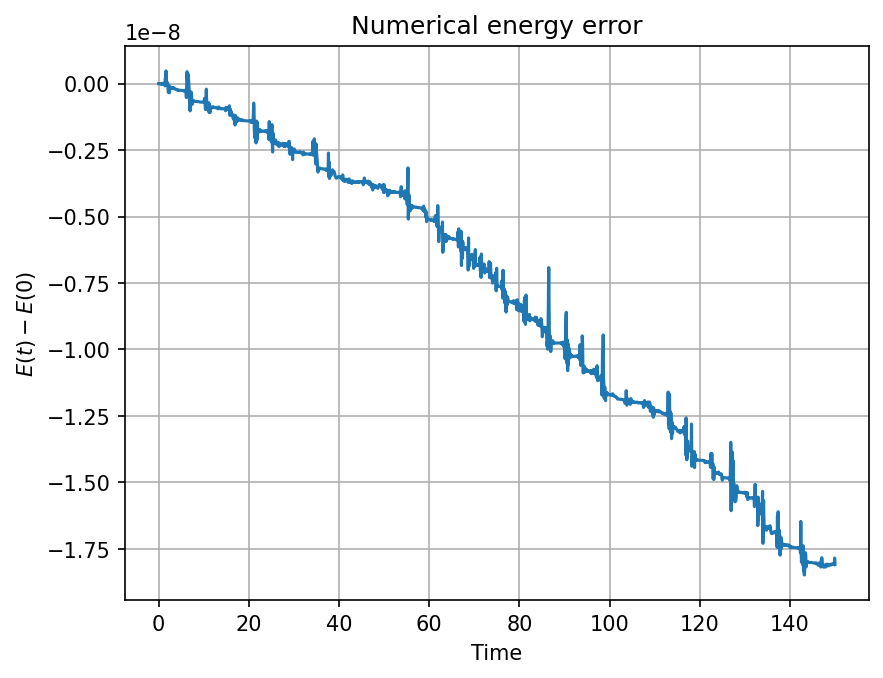

In [250]:
solution = problem.simulate(initial_states[0, :], 0, 150, N_points=2000)
theta1, theta2, theta3, omega1, omega2, omega3 = solution.y
momentum_hist, energy_hist = problem.analyse(solution)
#Angular momentum
plt.figure(dpi=150)
plt.plot(solution.t, momentum_hist)
plt.xlabel("Time")
plt.ylabel("Angular momentum")
plt.title("Conservation of angular momentum")
plt.grid()
plt.show()

#Energy
plt.figure(dpi=150)
plt.plot(solution.t, energy_hist - energy_hist[0])
plt.xlabel("Time")
plt.ylabel(r"$E(t)-E(0)$")
plt.title("Numerical energy error")
plt.grid()
plt.show()

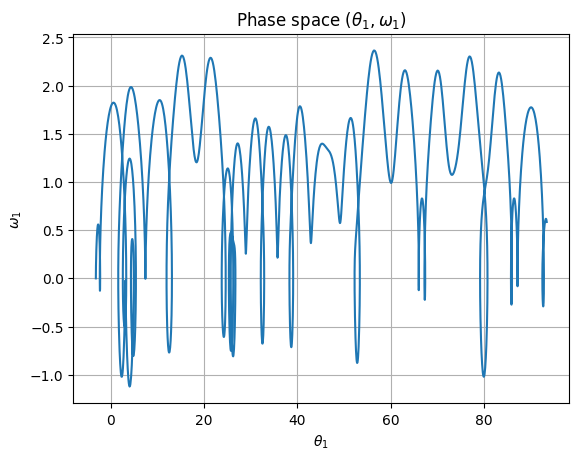

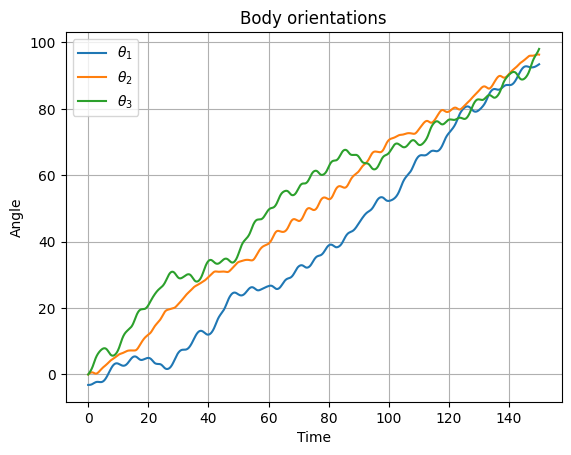

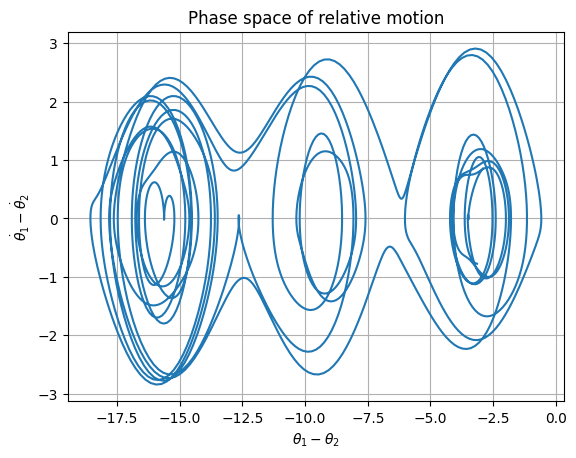

In [249]:
# Phase space
plt.figure()
plt.plot(theta1, omega1)
#plt.plot(theta2, omega2, label=r"")
plt.xlabel(r"$\theta_1$")
plt.ylabel(r"$\omega_1$")
plt.title(r"Phase space $(\theta_1, \omega_1)$")
#plt.legend()
plt.grid()
plt.show()
#Body orientations
plt.figure()
plt.plot(solution.t, theta1, label=r"$\theta_1$")
plt.plot(solution.t, theta2, label=r"$\theta_2$")
plt.plot(solution.t, theta3, label=r"$\theta_3$")
plt.xlabel("Time")
plt.ylabel("Angle")
plt.title("Body orientations")
plt.legend()
plt.grid()
plt.show()

# Relative motion between cylinder 1 and 2
plt.figure()
plt.plot(theta1-theta2, omega1-omega2)
plt.xlabel(r"$\theta_1-\theta_2$")
plt.ylabel(r"$\dot{\theta}_1-\dot{\theta}_2$")
plt.title("Phase space of relative motion")
plt.grid()
plt.show()

## Poincare Sections

63 crossings for state: [-3.14159265  0.          0.          0.          0.77459667  1.29099445]
58 crossings for state: [-2.82426006  0.          0.          0.          0.7550117   1.25835284]
57 crossings for state: [-2.50692747  0.          0.          0.          0.69509867  1.15849778]
61 crossings for state: [-2.12612836  0.          0.          0.          0.56243691  0.93739485]
59 crossings for state: [-1.80879577  0.          0.          0.          0.37610552  0.62684253]


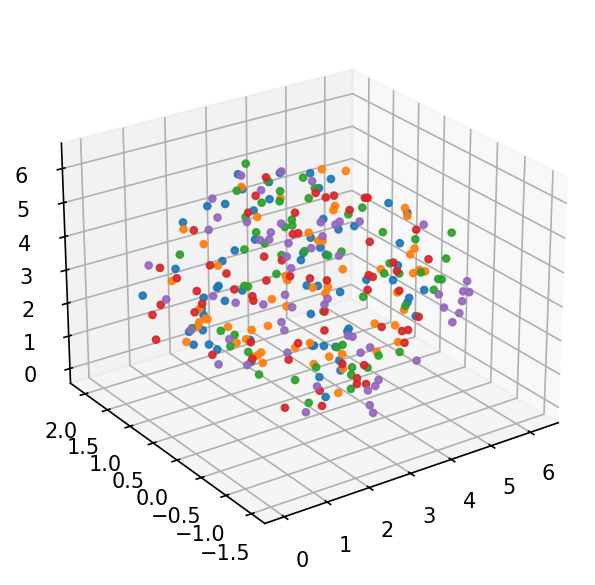

In [214]:
problem.Poincare_section(initial_states[:5, :], tf=1000, plotting_method='3D')

## Lyapunov Exponents

E=0.5 gives exponent ~0.19
E=1 gives exponent ~0.24

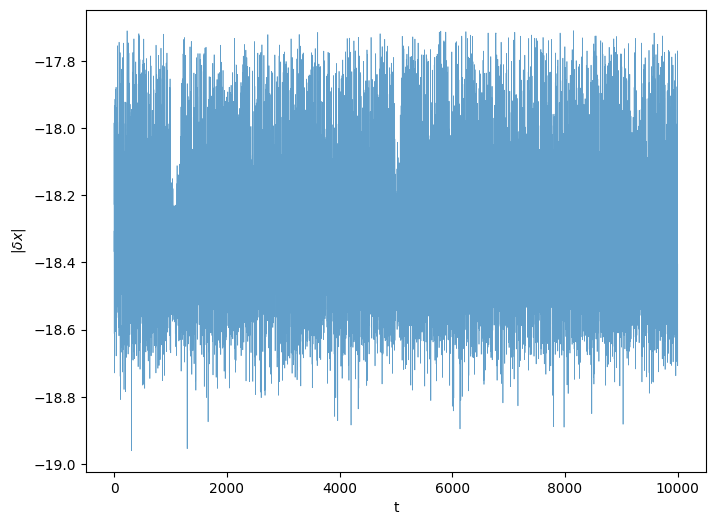

Lyapunov exponent: 2.722e-01


In [61]:
L_exponent = Lyapunov_exponent_coupled(
    problem.equations_of_motion,
    initial_states[1, :], 
    tf=10000, 
    dt=0.5, 
    drop_transient=True,
)
print(f"Lyapunov exponent: {L_exponent:.3e}")

In [219]:
avg = 0
for i in range(initial_states.shape[0]):
    L_exponent = Lyapunov_exponent_coupled(
        problem.equations_of_motion,
        initial_states[i, :], 
        tf=5000, 
        dt=0.5, 
        drop_transient=True,
        plotting=False,
    )
    avg += L_exponent / initial_states.shape[0]
    print(f"State {i+1}: {initial_states[i, :]}")
    print(f"Lyapunov exponent for state {i+1}: {L_exponent:.3e}")
print(f"Avg over the runs: {avg:.3e}")

State 1: [-3.14159265  0.          0.          0.          0.77459667  1.29099445]
Lyapunov exponent for state 1: 2.458e-01
State 2: [-2.82426006  0.          0.          0.          0.7550117   1.25835284]
Lyapunov exponent for state 2: 2.647e-01
State 3: [-2.50692747  0.          0.          0.          0.69509867  1.15849778]
Lyapunov exponent for state 3: 2.793e-01
State 4: [-2.12612836  0.          0.          0.          0.56243691  0.93739485]
Lyapunov exponent for state 4: 2.601e-01
State 5: [-1.80879577  0.          0.          0.          0.37610552  0.62684253]
Lyapunov exponent for state 5: 2.141e-01
State 6: [1.74532925 0.         0.         0.         0.32278306 0.53797177]
Lyapunov exponent for state 6: 2.169e-01
State 7: [2.06266184 0.         0.         0.         0.53231818 0.88719697]
Lyapunov exponent for state 7: 2.425e-01
State 8: [2.44346095 0.         0.         0.         0.67795772 1.12992953]
Lyapunov exponent for state 8: 2.696e-01
State 9: [2.76079354 0.   

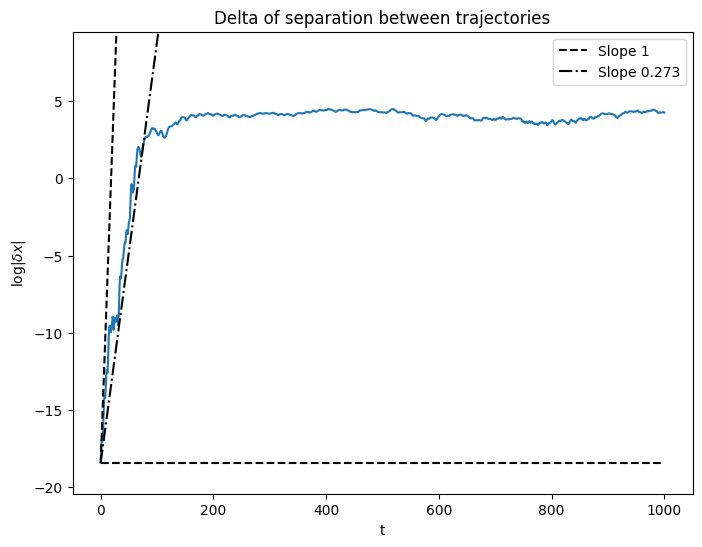

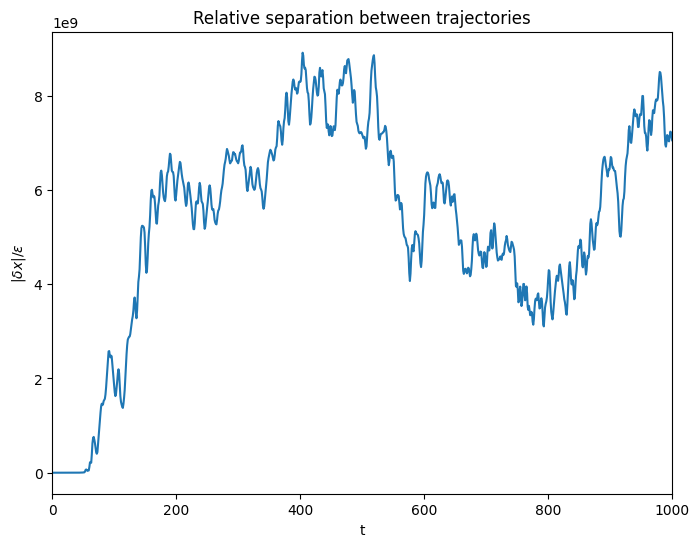

In [354]:
# Separation plot
separation_plot_coupled(problem.equations_of_motion, initial_states[0], tf=1000, dt=1)

# The Henon Heiles potential

Here we use the Henon Heiles potential as a playground to make sure our computations of Poincare sections and Lyapunov exponents are working.

[-0.4, 0.0, 0.0, 0.412310562561766]
[-0.32727272727272727, 0.0, 0.0, 0.47211498809450125]
[-0.2545454545454545, 0.0, 0.0, 0.514982146846129]
[-0.18181818181818182, 0.0, 0.0, 0.5449239843871166]
[-0.10909090909090907, 0.0, 0.0, 0.5640028134271309]
[-0.03636363636363632, 0.0, 0.0, 0.5733041827428205]
[0.036363636363636376, 0.0, 0.0, 0.5733041827428205]
[0.10909090909090913, 0.0, 0.0, 0.5640028134271309]
[0.18181818181818188, 0.0, 0.0, 0.5449239843871166]
[0.25454545454545463, 0.0, 0.0, 0.5149821468461289]
[0.3272727272727274, 0.0, 0.0, 0.4721149880945012]
[0.4, 0.0, 0.0, 0.412310562561766]


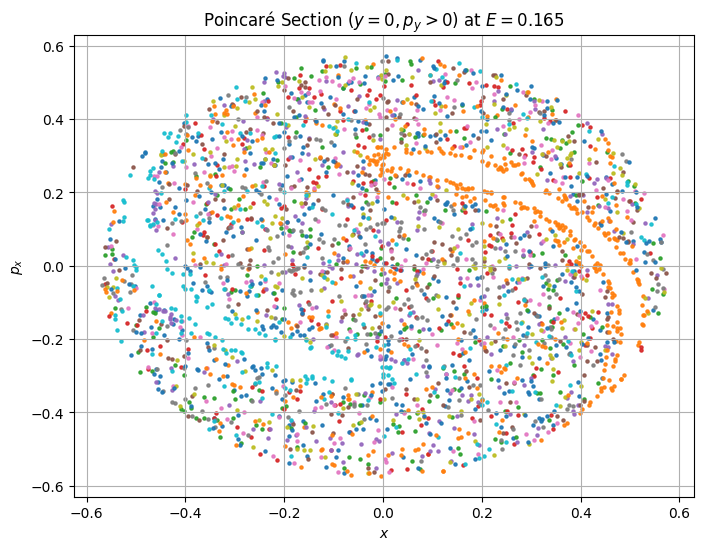

In [361]:
def henon_heiles(t, state):
    x, y, px, py = state
    dxdt = px
    dydt = py
    dpxdt = -x - 2*x*y
    dpydt = -y - x**2 + y**2
    return [dxdt, dydt, dpxdt, dpydt]

# Event function: Detect y = 0 crossing with py > 0 (increasing y)
def event_y_zero(t, state):
    return state[1]

event_y_zero.direction = 1  # py > 0

# Energy level E
E = 0.165  # Lower E = mostly regular; Higher E (e.g., 0.16667) = strongly chaotic

plt.figure(figsize=(8, 6))

# Sample different initial conditions (x, px) at y = 0
x_vals = np.linspace(-0.4, 0.4, 12)

for x0 in x_vals:
    # Compute px0 to ensure kinetic energy is non-negative
    V_0 = 0.5 * x0**2  # V(x0, y=0)
    max_px2 = 2 * (E - V_0)
    if max_px2 <= 0:
        continue
    
    px0 = 0.0
    py0 = np.sqrt(max_px2 - px0**2)
    
    initial_state = [x0, 0.0, px0, py0]
    print(initial_state)
    t_span = (0, 2000)
    
    # Solve ODE with event tracking
    sol = solve_ivp(
        henon_heiles, 
        t_span, 
        initial_state, 
        events=event_y_zero, 
        rtol=1e-9, 
        atol=1e-9,
        method='DOP853'
    )
    
    # Extract x and px at crossing events
    if len(sol.y_events[0]) > 0:
        x_crossings = sol.y_events[0][:, 0]
        px_crossings = sol.y_events[0][:, 2]
        plt.scatter(x_crossings, px_crossings, s=5, alpha=0.9, label=fr"$x_0=${initial_state[0]:.2f}")

plt.xlabel('$x$')
plt.ylabel('$p_x$')
plt.title(f'Poincaré Section ($y=0, p_y>0$) at $E = {E}$')
plt.grid(True)
#plt.legend()
plt.show()

Possibly Chaotic ICS for E=0.125: x0 = +-0.25454545, +-0.18181818

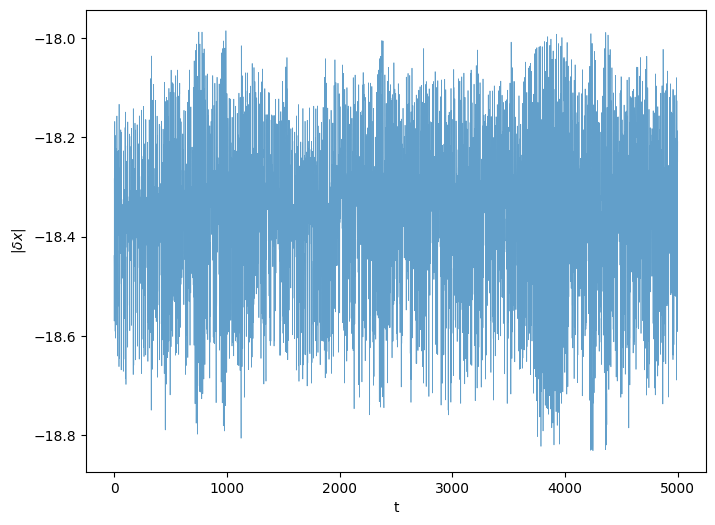

Estimated Lyapunov exponent: 1.256e-01


In [ ]:
# Try to get Lyapunov exponent of Henon-Heiles flow
# According to https://www.researchgate.net/publication/225605045_Lyapunov_exponents_in_the_Henon-Heiles_problem
# it should be about 0.05 for energy level 0.125
# log(L) = 3.6*log(E)+1.95
# But this depends on the trajectory we follow, since some will be regular at this energy level.
#initial_state = np.array([-0.4, 0.0, 0.0, 0.29999999999999993]) # Not chaotic, should get L~0
#initial_state = np.array([-0.18181818181818182, 0.0, 0.0, 0.46577048936179993]) # Possibly chaotic, should get L~0.05 (we get 5.465e-02)
initial_state = np.array([-0.4, 0.0, 0.0, 0.412310562561766]) # Very chaotic (E=0.165), should get L~0.136 (we get 1.256e-01)
L_exponent = Lyapunov_exponent_coupled(
    henon_heiles,
    initial_state, 
    tf=5000, 
    dt=0.5, 
    drop_transient=True, 
    adaptive_rescaling=False
)
print(f"Estimated Lyapunov exponent: {L_exponent:.3e}")

In [365]:
#initial_state = np.array([-0.18181818181818182, 0.0, 0.0, 0.46577048936179993]) # Possibly chaotic, should get L~0.05 (we get 5.465e-02)
initial_state = np.array([-0.4, 0.0, 0.0, 0.412310562561766]) # Very chaotic (E=0.165), should get L~0.136 (we get 1.256e-01)
L_avg = 0
runs = 5
for i in range(runs):
    L_exponent = Lyapunov_exponent_coupled(
        henon_heiles,
        initial_state, 
        tf=3000,
        dt=0.5, 
        drop_transient=True, 
        adaptive_rescaling=False,
        plotting=False
    )
    L_avg += L_exponent/runs
    print(f"Estimated Lyapunov exponent: {L_exponent:.3e}")
print(f"Avg exponent: {L_avg:.4e}")

Estimated Lyapunov exponent: 1.214e-01
Estimated Lyapunov exponent: 1.344e-01
Estimated Lyapunov exponent: 1.249e-01
Estimated Lyapunov exponent: 1.331e-01
Estimated Lyapunov exponent: 1.129e-01
Avg exponent: 1.2536e-01
